# innovfromtext demo: A measure of the most innovative American films

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/juliuskoschnick/innovfromtext/blob/main/examples/innovfromtext_movies.ipynb)

A short demo of the innovation index from [Koschnick (2025)](https://arxiv.org/abs/2512.16587) applied to movie plots: For the sake of this demo we define that a film is innovative if its plot is closer to the films of the following years than to the films of the preceding years.

**Data.** [`NiklasAbraham/MoviePlotEmbeddingsDataset`](https://huggingface.co/datasets/NiklasAbraham/MoviePlotEmbeddingsDataset) on Hugging Face: Wikipedia plot summaries of 92,374 feature films, 1930–2024, with `BAAI/bge-m3` embedding of every plot (licence CC BY-NC 4.0). We keep the American films and pass the dataset's embeddings to `innovfromtext`, so a CPU runtime is enough. The download is about 400 MB.

In [1]:
try:
    import innovfromtext
except ImportError:
    %pip install -q git+https://github.com/juliuskoschnick/innovfromtext.git

In [2]:
import numpy as np
import pandas as pd
from huggingface_hub import hf_hub_download
import innovfromtext as ift

pd.set_option("display.max_colwidth", None)
REPO ="NiklasAbraham/MoviePlotEmbeddingsDataset"
films = pd.read_csv(hf_hub_download(REPO, "final_dataset.csv", repo_type="dataset"),
                    usecols=["title", "year", "country", "plot", "vote_count", "vote_average"], low_memory=False)
emb = np.load(hf_hub_download(REPO, "final_dense_embeddings.npy", repo_type="dataset"))  # row i: plot of film i

us = films["country"].fillna("").str.startswith("United States").to_numpy()
df = films[us].reset_index(drop=True).assign(subject="American film")   # one field: American films
emb = emb[us]
print(f"{len(df):,} American films, {df.year.min()}-{df.year.max()} | embeddings {emb.shape}")

35,388 American films, 1930-2024 | embeddings (35388, 1024)


## 1. One film: *Star Wars* (1977)

**Intuition.** A text is innovative if it differs from what came before and is taken up by what comes after. The index measures this as a ratio: The similarity of a text to the later texts of its field, divided by its similarity to the earlier ones. Above one, a text resembles the future of its field more than its past. We now apply this to movie plots: A film is innovative if the films released after it tell stories closer to its plot than the films released before it.

$$\mathrm{Innovation}_{i} = \frac{f^k(v_i, \mathcal{F}_{t,\tau})}{f^k(v_i, \mathcal{B}_{t,\tau})}$$

$f^k$ is the mean cosine similarity between a film and its $k$ most similar films in a pool, $\mathcal{F}_{t,\tau}$ holds the films of the $\tau$ years after its release and $\mathcal{B}_{t,\tau}$ those of the $\tau$ years before. Films change faster than eighteenth-century science, so we use $\tau = 10$ years in both directions (`backward_window=10`) and $k = 20$. `subset` computes the index for one film only, while all films stay in the pools; `return_similarities=True` also returns the numerator and the denominator.

In [3]:
ARGS = dict(text="plot", year="year", subject="subject", tau=10, k=20, backward_window=10, embeddings=emb, show_progress=False)

star_wars = df["title"].eq("Star Wars: Episode IV – A New Hope")
one = ift.compute(df, "innovation", subset=star_wars, return_similarities=True, **ARGS)
one.loc[star_wars, ["title", "year", "forward_similarity", "backward_similarity", "innovation"]]

,title,year,forward_similarity,backward_similarity,innovation
12759,Star Wars: Episode IV – A New Hope,1977,0.649632,0.591747,1.097821


*Star Wars* has an index of 0.650 / 0.592 = 1.098: its 20 most similar films of 1978–1987 are on average about 10 per cent more similar to its plot than its 20 most similar films of 1967–1976. An index above one means that a film resembles the films after it more than the films before it. Its closest films in the forward pool are its own sequels.

## 2. Every film

The same call without `subset`. Films from the first and last ten years of the data have incomplete windows and get a missing index (`complete_windows=True`). The level of the index varies with the size of the pools, so we also rank films within their release year.

In [4]:
inn = ift.compute(df, "innovation", **ARGS).dropna(subset=["innovation"])
inn["pct_in_year"] = inn.groupby("year")["innovation"].rank(pct=True)
print(f"index for {len(inn):,} films, {inn.year.min()}-{inn.year.max()}")
inn["innovation"].describe().round(3)

index for 26,567 films, 1940-2014


count    26567.000
mean         1.002
std          0.018
min          0.835
25%          0.993
50%          1.002
75%          1.012
max          1.191
Name: innovation, dtype: float64

## 3. The most innovative films of each decade

We divide each film's index by the mean of its release year and keep films with at least 1,000 TMDb votes, so we can validate the results.

In [5]:
inn["rel_to_year"] = inn["innovation"] / inn.groupby("year")["innovation"].transform("mean")
known = inn[inn["vote_count"] >= 1000].assign(decade=lambda d: d.year // 10 * 10)
top = (known.sort_values("rel_to_year", ascending=False)
       .groupby("decade").head(4)
       .assign(film=lambda d: d.title + " (" + d.year.astype(str) + ")")
       .groupby("decade")["film"].agg(" | ".join))
for decade, films_ in top.items():
    print(f"{decade}s: {films_}")

1940s: Double Indemnity (1944) | It's a Wonderful Life (1946) | Casablanca (1942) | The Treasure of the Sierra Madre (1948)
1950s: The Day the Earth Stood Still (1951) | Forbidden Planet (1956) | Sleeping Beauty (1959) | The Ten Commandments (1956)
1960s: Goldfinger (1964) | Easy Rider (1969) | The Magnificent Seven (1960) | Cool Hand Luke (1967)
1970s: Star Wars: Episode IV – A New Hope (1977) | Star Trek: The Motion Picture (1979) | Rocky (1976) | Superman (1978)
1980s: Friday the 13th Part 2 (1981) | The Karate Kid (1984) | RoboCop (1987) | Police Academy (1984)
1990s: Bram Stoker's Dracula (1992) | American Pie (1999) | The Prince of Egypt (1998) | Balto (1995)
2000s: Harry Potter and the Philosopher's Stone (2001) | Superman Returns (2006) | Scooby-Doo (2002) | Harry Potter and the Chamber of Secrets (2002)
2010s: Justice League: The Flashpoint Paradox (2013) | Batman: Assault on Arkham (2014) | The Hunger Games (2012) | The Conjuring (2013)


The list is genuinely interesting (and an "objective" measure of plot influence). I had the chance to discuss it with some movie enthusiasts and will most likely do so in the future. 

My own take. It includes some of my absolute favourite movies, including "It's a Wonderful Life". Most titles are recognizable. Interestingly, many plot innovations are not "high art", but e.g. the introduction of comic characters. Undoubtedly, they changed the genres within the movie industry, so this seems to make sense.

(Note that many of these are franchises - in a way, their influence partly works through their sequels - worth playing around with, but also not wrong in itself. Having a sequel is clearly a mark of influence)


## 4. Validation: innovation and TMDb ratings

Next, we can test whether this new innovation index corresponds to viewer ratings. We use the TMDb database and create a simple binscatterplot:

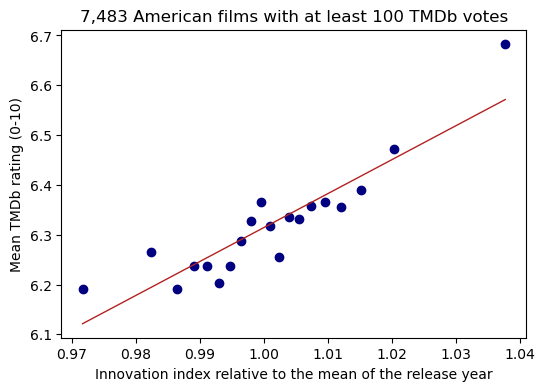

correlation of index and rating: 0.12


In [6]:
import matplotlib.pyplot as plt

v = inn[inn["vote_count"] >= 100]
bins = v.groupby(pd.qcut(v["rel_to_year"], 20, labels=False))[["rel_to_year", "vote_average"]].mean()
slope, const = np.polyfit(v["rel_to_year"], v["vote_average"], 1)

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(bins["rel_to_year"], bins["vote_average"], color="navy")
x = np.array([bins["rel_to_year"].min(), bins["rel_to_year"].max()])
ax.plot(x, const + slope * x, color="firebrick", lw=1)
ax.set(xlabel="Innovation index relative to the mean of the release year", ylabel="Mean TMDb rating (0-10)",
       title=f"{len(v):,} American films with at least 100 TMDb votes")
plt.show()
print(f"correlation of index and rating: {v['rel_to_year'].corr(v['vote_average']):.2f}")

Indeed there's a clear positive correlation. Films with a higher index are rated higher: The mean rating rises from about 6.2 in the lowest bins to 6.7 in the highest. The correlation is modest (0.12), after all our index is just based on plot summaries alone - and there's more to a film than that. Still, this is quite a nice result.